# Exploratory Data Analysis — features, targets and predictions

This notebook is the project's **EDA deliverable**. It inspects the
analysis-ready dataset (`data/gold/features.parquet` joined with
`target_labels.parquet`) and the model's out-of-sample predictions, and
answers four questions:

1. **What are we predicting?** — the distribution of the prediction target
   (`TO_PREDICT = future_return_3d`, the return over the *next 3 trading
   sessions*) and its up/down balance.
2. **Which features relate to it?** — Spearman and Pearson correlation of
   all engineered features against the target, plus a year-by-year
   stability check.
3. **How do predictions and precision differ by ticker?** — per-ticker
   information coefficients and the precision of the names the strategy
   actually selects each week.
4. **Where does it go wrong?** — an error analysis of the worst misses,
   with improvement ideas.

Data provenance: free public sources only (Yahoo Finance, RBA, ABS, ASIC,
Wikipedia), assembled by the pipeline demonstrated in
[`02_end_to_end_workflow.ipynb`](02_end_to_end_workflow.ipynb).

> **Research only — not financial advice.**

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

GOLD = Path("data/gold")
TO_PREDICT = "future_return_3d"  # the label every model is trained to predict
META_COLS = ["ticker", "date", "liquid_flag", "feature_set_version", "ingestion_run_id",
             "retrieved_at"]
LABEL_COLS = [
    "future_return_3d", "direction_3d", "label_available_date_3d",
    "future_return_10d", "direction_10d", "label_available_date_10d",
]

features = pd.read_parquet(GOLD / "features.parquet")
labels = pd.read_parquet(GOLD / "target_labels.parquet")
# features = every numeric column that is neither metadata nor a label
FEATURE_COLS = [
    c for c in features.columns
    if c not in META_COLS and c not in LABEL_COLS
    and pd.api.types.is_numeric_dtype(features[c])
]
print(f"features: {len(features):,} rows x {len(FEATURE_COLS)} feature columns "
      f"({features['date'].min()} -> {features['date'].max()})")

# One combined data frame: features (known at each close) + labels (the future).
df = features.merge(
    labels[["ticker", "date", "future_return_3d", "direction_3d", "future_return_10d"]],
    on=["ticker", "date"],
    how="inner",
)
print(f"joined features + labels: {len(df):,} rows")

features: 455,168 rows x 65 feature columns (2016-11-14 00:00:00 -> 2026-11-13 00:00:00)


joined features + labels: 455,168 rows


## 1. The prediction target

`TO_PREDICT = future_return_3d` is the stock's return from its close on day
*t* to its close three trading sessions later (labels are computed on
adjusted closes and live in a separate gold table, `target_labels.parquet`,
so the feature columns can never accidentally contain them).

count    454583.000000
mean          0.002331
std           0.049624
min          -0.872001
25%          -0.016654
50%           0.000365
75%           0.019469
max           9.666972

share of stock-days with positive next-3d return (direction_3d == 1): 0.500


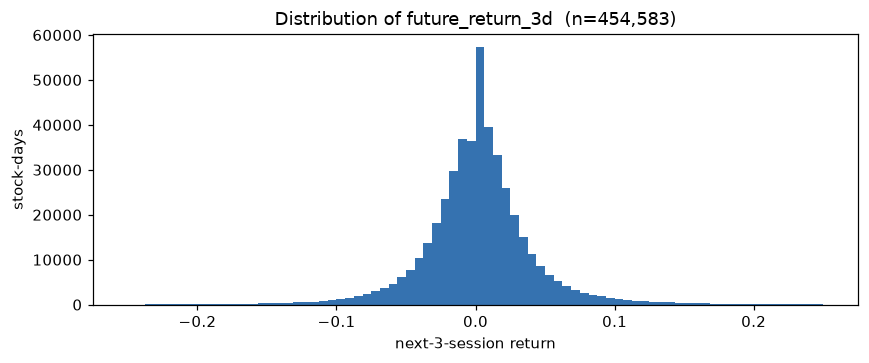

In [2]:
target = df[TO_PREDICT].dropna()
print(target.describe().to_string())
print(f"\nshare of stock-days with positive next-3d return "
      f"(direction_3d == 1): {(df['direction_3d'] == 1).mean():.3f}")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(target, bins=80, range=(-0.25, 0.25), color="#3572b0")
ax.set_title(f"Distribution of {TO_PREDICT}  (n={len(target):,})")
ax.set_xlabel("next-3-session return")
ax.set_ylabel("stock-days")
fig.tight_layout()
plt.show()

Typical of short-horizon equity returns: a near-zero mean, fat tails, and a
roughly balanced up/down split. Any real, learnable edge is small relative
to this noise — which is exactly why the models are evaluated on *ranking*
quality (Spearman IC) rather than raw return prediction error.

## 2. Correlation of every feature with `TO_PREDICT`

Spearman (rank) correlation is the more robust lens for skewed returns;
Pearson is shown for reference. Both are pooled over the full 2016–2026
sample.

In [3]:
spearman = df[FEATURE_COLS].corrwith(df[TO_PREDICT], method="spearman")
pearson = df[FEATURE_COLS].corrwith(df[TO_PREDICT], method="pearson")
corr = pd.DataFrame({"spearman": spearman, "pearson": pearson}).sort_values("spearman")

print("weakest 8 (negative side):")
print(corr.head(8).round(4).to_string())
print("\nstrongest 8 (positive side):")
print(corr.tail(8).round(4).to_string())

weakest 8 (negative side):
                        spearman  pearson
price_to_sma_5           -0.0356  -0.0130
return_1d                -0.0344  -0.0139
return_3d                -0.0304  -0.0043
bench_close_to_sma_100   -0.0290  -0.0284
price_to_sma_10          -0.0289  -0.0078
return_5d                -0.0275  -0.0074
bollinger_pctb           -0.0255  -0.0133
rsi_14                   -0.0239  -0.0155

strongest 8 (positive side):
                             spearman  pearson
volatility_5d                  0.0041   0.0264
volatility_20d                 0.0060   0.0401
volatility_10d                 0.0066   0.0391
volatility_60d                 0.0086   0.0380
volume_ratio_5d                0.0099   0.0100
macro_abs_unemployment_rate    0.0110   0.0141
macro_curve_slope_10y_2y       0.0168   0.0145
bench_volatility_20d           0.0260   0.0431


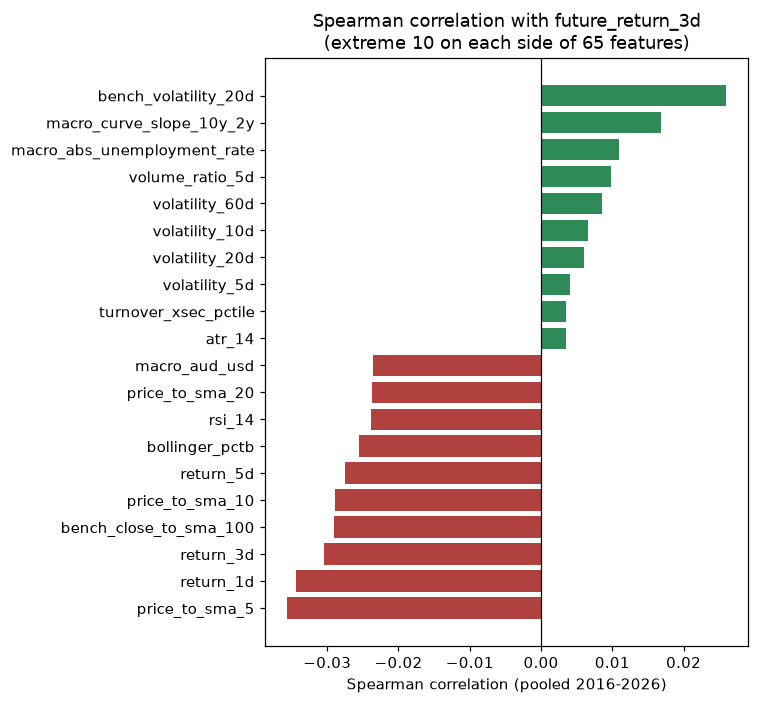

In [4]:
top = pd.concat([corr.head(10), corr.tail(10)]).sort_values("spearman")
colors = np.where(top["spearman"] > 0, "#2e8b57", "#b0413e")
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(top.index, top["spearman"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title(f"Spearman correlation with {TO_PREDICT}\n"
             f"(extreme 10 on each side of {len(corr)} features)")
ax.set_xlabel("Spearman correlation (pooled 2016-2026)")
fig.tight_layout()
plt.show()

Every single-feature correlation is small — of the order of a few percent
at best. That is the honest, expected picture for 3-day stock returns: no
single indicator carries the signal; the value (if any) comes from combining
many weak hints, which is what the gradient-boosting model in Phase 5 does.

### Are the relationships stable over time?

A correlation that flips sign by year is regime-dependent, not a law. The
plot below re-computes the Spearman IC of the six strongest features inside
each calendar year.

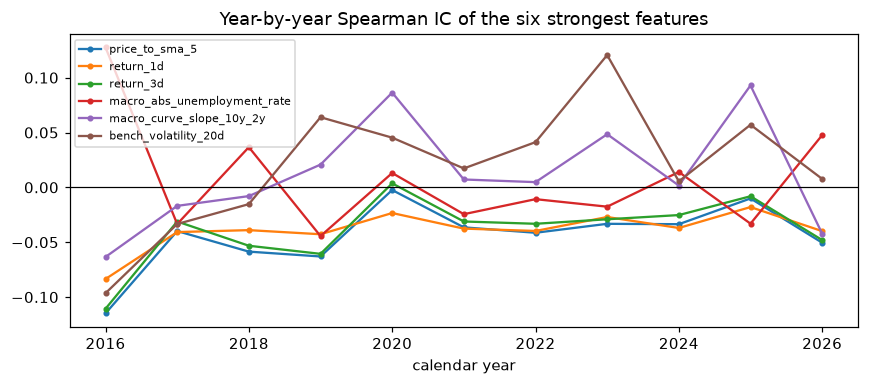

In [5]:
focus = list(pd.concat([corr.head(3), corr.tail(3)]).index)
df["year"] = pd.to_datetime(df["date"]).dt.year
stability = pd.DataFrame({
    year: group[focus].corrwith(group[TO_PREDICT], method="spearman")
    for year, group in df.groupby("year")
}).T.sort_index()

fig, ax = plt.subplots(figsize=(8, 3.6))
for name in focus:
    ax.plot(stability.index, stability[name], marker="o", ms=3, label=name)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Year-by-year Spearman IC of the six strongest features")
ax.set_xlabel("calendar year")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Read this before trusting any backtest: the per-year lines wobble around
zero and some change sign. Relationships on a 3-day horizon are weak and
regime-dependent — the reason the project trains with walk-forward
cross-validation (always train on the past, test on the next chunk) instead
of one global fit, and why a small pooled IC of ~0.03 is treated as a
*whisper*, not a law.

## 3. Per-ticker prediction quality

Out-of-sample predictions of the **selected model** (`hist_gbt_reg`) are
joined with realised labels, and one Spearman IC is computed per ticker
(tickers with fewer than 250 predictions are skipped). The spread across
tickers matters for the portfolio: averaging a mix of good and
anti-predictable names dilutes the edge.

In [6]:
preds = pd.read_parquet(GOLD / "predictions.parquet")
preds = preds[preds["model_name"] == "hist_gbt_reg"]  # the selected model
pp = preds.merge(
    labels[["ticker", "date", "future_return_3d"]],
    on=["ticker", "date"],
    how="inner",
)
print(f"selected-model predictions with a realised label: {len(pp):,}")


def ticker_ic(group: pd.DataFrame) -> float:
    if len(group) < 250:
        return np.nan
    return group[["prediction", "future_return_3d"]].corr(method="spearman").iloc[0, 1]


tic = pp.groupby("ticker").apply(ticker_ic, include_groups=False).dropna().sort_values()
print(f"tickers with >= 250 predictions: {len(tic)}; mean per-ticker IC: {tic.mean():+.4f}")
print("\nmost predictable 8:")
print(tic.tail(8).round(3).to_string())
print("\nleast predictable 8:")
print(tic.head(8).round(3).to_string())

selected-model predictions with a realised label: 283,957


tickers with >= 250 predictions: 194; mean per-ticker IC: +0.0017

most predictable 8:
ticker
RSG.AX    0.066
MEZ.AX    0.075
BFL.AX    0.078
AGL.AX    0.084
ASX.AX    0.097
GGP.AX    0.122
CEN.AX    0.156
MCY.AX    0.165

least predictable 8:
ticker
VGN.AX   -0.087
ANN.AX   -0.086
PME.AX   -0.086
SGM.AX   -0.068
MIN.AX   -0.067
ARG.AX   -0.061
NXT.AX   -0.059
DRR.AX   -0.057


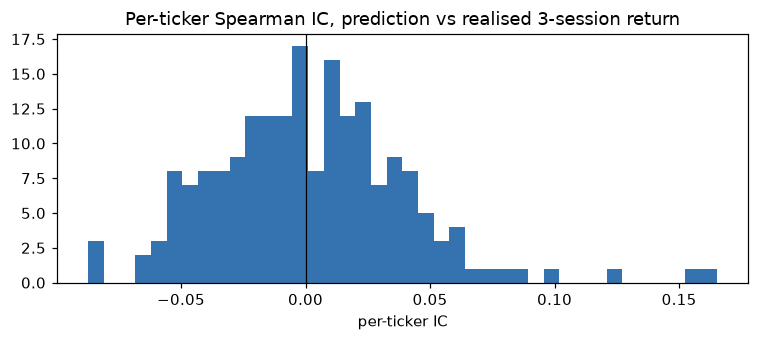

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(tic, bins=40, color="#3572b0")
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Per-ticker Spearman IC, prediction vs realised 3-session return")
ax.set_xlabel("per-ticker IC")
fig.tight_layout()
plt.show()

The dispersion around zero is wide: a handful of tickers are reliably
predictable and a similar handful are *anti*-predictable (high predicted
return followed by a fall). Ideas this suggests: down-weight or exclude
persistent negative-IC names, or size positions by per-ticker confidence.
Any such rule must itself be validated walk-forward before it earns a place
in the pipeline.

## 4. Precision of the names actually selected

The strategy holds the top-20 ranked stocks each Monday. "Precision" here:
the share of selected names whose realised next-3-session return was
positive — compared against the same-day universe baseline (the share of
*all* stocks that rose over the next 3 sessions).

In [8]:
port = pd.read_parquet(GOLD / "target_portfolios.parquet")
sel = port.merge(
    labels[["ticker", "date", "future_return_3d", "direction_3d"]],
    left_on=["ticker", "rebalance_date"],
    right_on=["ticker", "date"],
    how="left",
)
precision = (sel["direction_3d"] == 1).mean()
baseline = (df[df["date"].isin(port["rebalance_date"])]["direction_3d"] == 1).mean()
print(f"selected names positive over next 3 sessions: {precision:.3f}")
print(f"universe baseline on the same dates:          {baseline:.3f}")

sel["year"] = pd.to_datetime(sel["rebalance_date"]).dt.year
by_year = sel.groupby("year").agg(
    precision=("direction_3d", lambda s: (s == 1).mean()),
    n=("direction_3d", "size"),
)
print(by_year.round(3).to_string())

selected names positive over next 3 sessions: 0.517
universe baseline on the same dates:          0.514
      precision     n
year                 
2020      0.531   160
2021      0.525  1040
2022      0.522  1040
2023      0.496  1040
2024      0.518  1060
2025      0.543  1040
2026      0.493   900


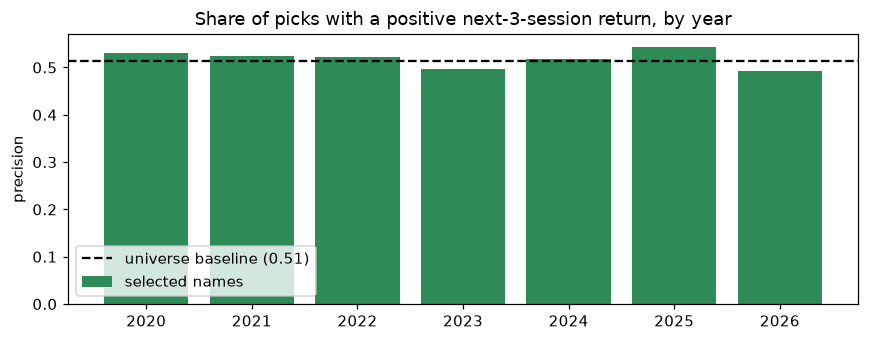

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(by_year.index.astype(str), by_year["precision"], color="#2e8b57", label="selected names")
ax.axhline(baseline, color="black", ls="--", label=f"universe baseline ({baseline:.2f})")
ax.set_title("Share of picks with a positive next-3-session return, by year")
ax.set_ylabel("precision")
ax.legend()
fig.tight_layout()
plt.show()

Selection adds only a slim hit-rate edge over the same-day universe
baseline (see the output: pooled and per-year figures). Individual years
sit on both sides of the baseline — the edge is a whisper, not a law. The
backtest (Phase 7) shows why even this thin edge did not survive trading
costs: weekly turnover of ~56% spent AUD ~94k in fees, more than the edge
was worth.

## 5. Error analysis — the worst misses

Among all selected (ticker, date) picks, which were the worst realised
losses, and did they share a feature profile?

In [10]:
sel_named = sel[sel["future_return_3d"].notna()].copy()
worst = sel_named.nsmallest(10, "future_return_3d")
print("ten worst picks:")
print(worst[["rebalance_date", "ticker", "rank", "signal", "future_return_3d"]]
      .to_string(index=False))

ten worst picks:
rebalance_date ticker  rank    signal  future_return_3d
    2022-06-27 EOS.AX    16  0.003539         -0.324675
    2022-02-21 360.AX     2  0.025215         -0.306667
    2025-11-17 DRO.AX     1  0.019923         -0.273077
    2022-03-14 SMR.AX     7 -0.013392         -0.227027
    2025-10-13 EOS.AX     1  0.023348         -0.226268
    2025-01-28 ZIP.AX    18 -0.000216         -0.225397
    2022-12-05 DOW.AX    16  0.001414         -0.220408
    2022-10-24 CDA.AX    10  0.000870         -0.212679
    2020-11-09 RMS.AX    15 -0.010096         -0.211539
    2025-09-08 LTR.AX     3  0.016941         -0.211340


In [11]:
PROF_COLS = [
    "volatility_20d", "beta_252d", "atr_14", "pct_from_63d_high",
    "momentum_ts_pctile_63d", "dollar_turnover_20d",
]
# bring the feature values of each pick alongside its realised outcome
prof_df = sel_named.merge(
    features[["ticker", "date"] + PROF_COLS],
    left_on=["ticker", "rebalance_date"],
    right_on=["ticker", "date"],
    how="left",
)
misses = prof_df[prof_df["future_return_3d"] <= prof_df["future_return_3d"].quantile(0.10)]
profile = prof_df[PROF_COLS].mean().rename("all picks").to_frame()
profile["worst 10% of picks"] = misses[PROF_COLS].mean()
print(profile.round(4).to_string())

                           all picks  worst 10% of picks
volatility_20d          4.933000e-01        6.321000e-01
beta_252d               1.123400e+00        1.286400e+00
atr_14                  4.104000e-01        3.720000e-01
pct_from_63d_high      -2.262000e-01       -2.402000e-01
momentum_ts_pctile_63d  4.248000e-01        4.482000e-01
dollar_turnover_20d     1.963009e+07        1.939393e+07


## Conclusions and improvement ideas

* **The target is close to noise**: near-zero mean, fat tails, balanced
  up/down; every single-feature correlation is small, and per-year ICs
  wobble and sometimes flip sign. Walk-forward validation was the right
  call; a pooled IC of ~0.03 is a whisper, not an edge.
* **Selection does rank better than chance** — selected names beat the
  same-day universe hit rate, consistently but narrowly.
* **Per-ticker dispersion is real**: both strongly-predictable and
  anti-predictable tickers exist. Candidate improvements: exclude or
  down-weight persistent negative-IC names; confidence-weighted sizing.
* **Costs, not signal, decide the outcome**: the thin edge paid for a very
  expensive trading pattern. Candidate improvements, in likely order of
  impact: a lower-turnover rebalance (the sensitivity grid already shows
  monthly rebalancing lifts Sharpe from ~-0.10 to ~0.90), a longer
  prediction horizon (the 10-session label exists but no model is trained
  on it yet), and only trading when the expected edge after costs is
  positive (a probability/return-threshold rule).
* Nothing here has been *proved* tradable: these are research insights
  intended to seed the next, equally honest, round of walk-forward
  experiments.